# Домашняя работа: квантизация и дистилляция LLM

В этой работе вы самостоятельно проведёте эксперименты с квантизацией и дистилляцией LLM и проверите, сколько качества при этом теряет модель. Задача, на которую обучаемся, — разбор запросов к голосовому ассистенту из датасета MASSIVE (ru-RU): по запросу модель возвращает JSON с intent и slots. Подробнее: https://huggingface.co/datasets/AmazonScience/massive

### Сперва настроим окружение и подготовим код для экспериментов

In [1]:
from pathlib import Path
print(Path('requirements.txt').read_text())

torch==2.8.0
transformers==4.55.2
datasets==4.1.1
accelerate==1.10.1
llmcompressor==0.8.1
compressed-tensors==0.12.2
numpy==2.2.6
pandas==2.2.3
safetensors==0.5.3
huggingface-hub==0.34.3
tqdm==4.67.1
ipykernel==6.30.1
nbclient==0.10.2



In [2]:
import hashlib
import json
import math
import subprocess
import sys
from importlib.metadata import version
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from transformers import set_seed

from data import (ARTIFACTS, BASE_MODEL_ID, BASE_REVISION, GENERATE_BATCH_SIZE, MAX_NEW_TOKENS, MAX_PROMPT_TOKENS, SEED, TEACHER_MODEL_ID, TEACHER_REVISION, encode_prompt, load_data, system_prompt)
from evaluate import compute_metrics, evaluate_checkpoint, generate_answer_ids, parse_answer, trim_answer
from distill import TeacherAnswerDataset, collate_teacher_answers

/home/mekashirskiy/dl-course-hw7-20261117/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
ARTIFACTS.mkdir(exist_ok=True)
set_seed(SEED)
configs = json.loads(Path('configs.json').read_text())
environment = {p: version(p) for p in ('torch', 'transformers', 'datasets', 'llmcompressor', 'compressed-tensors', 'numpy', 'safetensors')}
print(environment)

{'torch': '2.8.0', 'transformers': '4.55.2', 'datasets': '4.1.1', 'llmcompressor': '0.8.1', 'compressed-tensors': '0.12.2', 'numpy': '2.2.6', 'safetensors': '0.5.3'}


## Загрузка MASSIVE

Используем датасет MASSIVE. Все калибровочные примеры и данные для дистилляции берём только из train. Оцениваем на валидации (dev).

In [4]:
train_data, dev_data, INTENTS, SLOT_TYPES = load_data()
print({'train': len(train_data), 'dev': len(dev_data), 'intents': len(INTENTS), 'slot_types': len(SLOT_TYPES)})
print(json.loads((ARTIFACTS / 'data/manifest.json').read_text())['sha256'])

{'train': 11514, 'dev': 256, 'intents': 60, 'slot_types': 54}
{'train': '1941c777fee3e9e56e746ba56801b0349dfab2ea24a20b3706363569d40e36c2', 'dev': 'bfc837903a1c0ea8f939b5060dc5660f563edb1b12334f64679222a078c4316b'}


In [5]:
example_index = 0
example_prepared = train_data[example_index]
print(json.dumps(example_prepared, ensure_ascii=False, indent=2))

{
  "id": "1",
  "text": "разбуди меня в девять утра в пятницу",
  "gold": "{\"intent\":\"alarm_set\",\"slots\":[[\"time\",\"девять утра\"],[\"date\",\"пятницу\"]]}"
}


### Сконвертируем данные для калибровки

В MASSIVE текст запроса лежит в поле `utt`, intent записан числом, а slots отмечены прямо в тексте поля `annot_utt`, например `[time : семь утра]`. Модель должна по запросу вернуть JSON с названием intent и списком slots в виде пар «тип — значение». Поэтому преобразуем запись в `text` — исходный запрос — и `gold` — эталонный JSON-ответ. Такой формат удобнее для калибровки и подсчёта метрик.

In [6]:
from data import extract_slots, target_json

example = '[time : семь утра]'
print(extract_slots(example))
print(target_json('alarm_set', extract_slots(example)))

[['time', 'семь утра']]
{"intent":"alarm_set","slots":[["time","семь утра"]]}


In [7]:
print('Число классов:', len(INTENTS), 'типов slots:', len(SLOT_TYPES))
assert len(dev_data) == 256
assert not set(train_data['id']) & set(dev_data['id'])

Число классов: 60 типов slots: 54


In [8]:
print('Запрос модели:', example_prepared['text'])
print('Эталонный ответ:')
print(json.dumps(json.loads(example_prepared['gold']), ensure_ascii=False, indent=2))

Запрос модели: разбуди меня в девять утра в пятницу
Эталонный ответ:
{
  "intent": "alarm_set",
  "slots": [
    [
      "time",
      "девять утра"
    ],
    [
      "date",
      "пятницу"
    ]
  ]
}


### Генерация ответов
Всем моделям даём одинаковую инструкцию и одинаковые описания допустимых классов. Генерация детерминирована: greedy decoding, одинаковый лимит токенов.

In [9]:
print({'base': BASE_MODEL_ID, 'revision': BASE_REVISION, 'max_prompt': MAX_PROMPT_TOKENS, 'max_new': MAX_NEW_TOKENS, 'batch': GENERATE_BATCH_SIZE, 'seed': SEED})

{'base': 'Qwen/Qwen3-8B', 'revision': 'b968826d9c46dd6066d109eabc6255188de91218', 'max_prompt': 2048, 'max_new': 128, 'batch': 4, 'seed': 42}


In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID, revision=BASE_REVISION)
prompt = system_prompt(INTENTS, SLOT_TYPES)
print('Промпт, токенов:', len(encode_prompt(tokenizer, train_data[0]['text'], prompt)))
print('Greedy задан явно: use_model_defaults=False, do_sample=False')

Промпт, токенов: 504
Greedy задан явно: use_model_defaults=False, do_sample=False


In [11]:
def run_missing(command, artifact):
    if not Path(artifact).exists():
        subprocess.run([sys.executable, *command], check=True)

run_missing(['evaluate.py'], ARTIFACTS / 'evaluations/baseline.json')

## Метрика качества

$$
Q = \tfrac{1}{2} \operatorname{IntentAccuracy} + \tfrac{1}{2} \operatorname{SlotMicroF1}.
$$

Slots сравниваются как **мультимножество** пар `(тип, значение)`: порядок не влияет, лишние дубликаты дают false positives. Неверный JSON или нарушение схемы считается ошибкой всего ответа.

Дополнительно считаем `frame_exact_match` и `valid_json_rate`. Если во всей выборке нет ни одного gold/predicted slot, slot F1 равен 1 только при валидности всех ответов, иначе 0.

In [12]:
def checked_metrics(name):
    path = ARTIFACTS / 'evaluations' / f'{name}.jsonl'
    saved = json.loads(path.with_suffix('.json').read_text())
    records = [json.loads(line) for line in path.read_text().splitlines()]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == saved['predictions_sha256']
    assert [r['id'] for r in records] == dev_data['id']
    assert [r['gold'] for r in records] == dev_data['gold']
    metrics = compute_metrics([r['prediction'] for r in records], [r['gold'] for r in records], INTENTS, SLOT_TYPES)
    assert all(math.isclose(saved[key], value, abs_tol=1e-12) for key, value in metrics.items())
    assert saved['do_sample'] is False and saved['use_model_defaults'] is False
    return {'run': name, **metrics}

subprocess.run([sys.executable, '-m', 'unittest', '-q', 'test_solution.py'], check=True)

2026-11-17T06:42:33.853265+0300 | reset | INFO - Compression lifecycle reset
2026-11-17T06:42:33.871251+0300 | _create_default_logger | INFO - Logging all LLM Compressor modifier-level logs to sparse_logs/17-11-2026_06.42.33.log
2026-11-17T06:42:33.874899+0300 | from_modifiers | INFO - Creating recipe from modifiers
2026-11-17T06:42:33.889151+0300 | initialize | INFO - Compression lifecycle initialized for 1 modifiers
2026-11-17T06:42:33.890484+0300 | IndependentPipeline | INFO - Inferred `SequentialPipeline` for `GPTQModifier`
2026-11-17T06:42:33.894194+0300 | dispatch_for_sequential | WARNING - CUDA/XPU is not available! Compressing model on CPU instead


/home/mekashirskiy/dl-course-hw7-20261117/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/home/mekashirskiy/.local/share/uv/python/cpython-3.12.14-linux-x86_64-gnu/lib/python3.12/multiprocessing/popen_fork.py:66: DeprecationWarning: This process (pid=97569) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


/home/mekashirskiy/dl-course-hw7-20261117/.venv/lib/python3.12/site-packages/torch/fx/_symbolic_trace.py:148: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
  co.co_lnotab,
Preparing cache:   0%|          | 0/2 [00:00<?, ?it/s]/home/mekashirskiy/dl-course-hw7-20261117/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/home/mekashirskiy/.local/share/uv/python/cpython-3.12.14-linux-x86_64-gnu/lib/python3.12/multiprocessing/popen_fork.py:66: DeprecationWarning: This process (pid=97569) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
(1/2): Calibrating: 100%|██████████| 2/2 [00:00<00:00, 80.61it/s]


2026-11-17T06:42:34.448984+0300 | compress_modules | INFO - Quantizing model.layers.0.self_attn.q_proj using 2 samples
2026-11-17T06:42:34.462862+0300 | compress | METRIC - time 0.01s
2026-11-17T06:42:34.463712+0300 | compress | METRIC - error 0.00
2026-11-17T06:42:34.599637+0300 | compress | METRIC - GPU 0 | usage: 23.45% | total memory: 85 GB
2026-11-17T06:42:34.600416+0300 | compress | METRIC - GPU 1 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:34.600956+0300 | compress | METRIC - GPU 2 | usage: 34.35% | total memory: 85 GB
2026-11-17T06:42:34.601455+0300 | compress | METRIC - GPU 3 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.601928+0300 | compress | METRIC - GPU 4 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:34.602385+0300 | compress | METRIC - GPU 5 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.602933+0300 | compress | METRIC - GPU 6 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.603394+0300 | compress | METRIC - GPU 7 | usage:

2026-11-17T06:42:34.723004+0300 | compress | METRIC - GPU 0 | usage: 23.45% | total memory: 85 GB
2026-11-17T06:42:34.723803+0300 | compress | METRIC - GPU 1 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:34.724287+0300 | compress | METRIC - GPU 2 | usage: 34.35% | total memory: 85 GB
2026-11-17T06:42:34.724887+0300 | compress | METRIC - GPU 3 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.725659+0300 | compress | METRIC - GPU 4 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:34.726325+0300 | compress | METRIC - GPU 5 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.726791+0300 | compress | METRIC - GPU 6 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.727209+0300 | compress | METRIC - GPU 7 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.727666+0300 | compress | METRIC - Compressed module size: 0.00028 MB
2026-11-17T06:42:34.728233+0300 | compress_modules | INFO - Quantizing model.layers.0.self_attn.v_proj using 2 samples
2026-11-17T0

2026-11-17T06:42:34.976219+0300 | compress | METRIC - GPU 0 | usage: 23.45% | total memory: 85 GB
2026-11-17T06:42:34.977010+0300 | compress | METRIC - GPU 1 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:34.977638+0300 | compress | METRIC - GPU 2 | usage: 34.35% | total memory: 85 GB
2026-11-17T06:42:34.978134+0300 | compress | METRIC - GPU 3 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.978653+0300 | compress | METRIC - GPU 4 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:34.979226+0300 | compress | METRIC - GPU 5 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.979682+0300 | compress | METRIC - GPU 6 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.980073+0300 | compress | METRIC - GPU 7 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:34.980606+0300 | compress | METRIC - Compressed module size: 0.00056 MB
2026-11-17T06:42:34.981198+0300 | compress_modules | INFO - Quantizing model.layers.0.mlp.gate_proj using 2 samples
2026-11-17T06:4

2026-11-17T06:42:35.237769+0300 | compress | METRIC - GPU 0 | usage: 23.45% | total memory: 85 GB
2026-11-17T06:42:35.238589+0300 | compress | METRIC - GPU 1 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:35.239131+0300 | compress | METRIC - GPU 2 | usage: 34.35% | total memory: 85 GB
2026-11-17T06:42:35.239611+0300 | compress | METRIC - GPU 3 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:35.240106+0300 | compress | METRIC - GPU 4 | usage: 70.38% | total memory: 85 GB
2026-11-17T06:42:35.240553+0300 | compress | METRIC - GPU 5 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:35.240973+0300 | compress | METRIC - GPU 6 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:35.241440+0300 | compress | METRIC - GPU 7 | usage: 0.59% | total memory: 85 GB
2026-11-17T06:42:35.241964+0300 | compress | METRIC - Compressed module size: 0.00112 MB
2026-11-17T06:42:35.242567+0300 | compress_modules | INFO - Quantizing model.layers.0.mlp.down_proj using 2 samples
2026-11-17T06:4

(2/2): Propagating: 100%|██████████| 2/2 [00:00<00:00, 10046.24it/s]
Compressing model: 7it [00:00, 836.38it/s]


/home/mekashirskiy/dl-course-hw7-20261117/.venv/lib/python3.12/site-packages/transformers/quantizers/auto.py:231: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.However, loading attributes (e.g. ['run_compressed']) will be overwritten with the one you passed to `from_pretrained`. The rest will be ignored.
  warnings.warn(warning_msg)
Decompressing model: 7it [00:00, 3479.10it/s]
----------------------------------------------------------------------
Ran 11 tests in 20.198s

OK


CompletedProcess(args=['/home/mekashirskiy/dl-course-hw7-20261117/.venv/bin/python', '-m', 'unittest', '-q', 'test_solution.py'], returncode=0)

Посчитаем метрики бейзлайна.

In [13]:
baseline_metrics = checked_metrics('baseline')
display(pd.DataFrame([baseline_metrics]))

,run,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,n
0,baseline,0.291174,0.382812,0.199536,0.109375,0.53125,256


## Квантизация (5 баллов)

Используя код с семинара выполните следующие задания:
1) На примере одного из методов откалибруйте бейзлайн на MASSIVE train и на WikiText, сравните качество на dev. Есть ли влияние калибровочного датасета на метрику? (1 балл)

2) Поэкспериментируйте с разными конфигурациями методов AWQ, GPTQ, SmoothQuant (3 балла)

    Запустите минимум три конфигурации, пробуйте менять разные факторы:

    - битность
    - число калибровочных примеров;
    - group size
    - symmetric / asymmetric quantization;
    - smoothing_strength
    - Дополнительно (+1 балл) — какие слои оставить в исходной точности

3) Объясните результат — какие параметры наиболее значимы? (1 балл)


,run,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,n,method,calibration,samples,group_size,checkpoint_bytes,disk_ratio,alpha,last_block_bf16
0,awq_massive,0.314143,0.402344,0.225941,0.121094,0.566406,256,awq,massive,256,128.0,6071452776,2.698121,NaN,NaN
1,awq_wikitext,0.408799,0.535156,0.282443,0.128906,0.734375,256,awq,wikitext,256,128.0,6071452776,2.698121,NaN,NaN
2,gptq_g128,0.403740,0.589844,0.217636,0.144531,0.804688,256,gptq,massive,256,128.0,6071452776,2.698121,NaN,NaN
3,gptq_n64,0.324827,0.457031,0.192623,0.101562,0.656250,256,gptq,massive,64,128.0,6071452776,2.698121,NaN,NaN
4,gptq_g64,0.355270,0.484375,0.226164,0.148438,0.609375,256,gptq,massive,256,64.0,6179980432,2.650739,NaN,NaN
5,sq_a05,0.391802,0.535156,0.248447,0.140625,0.703125,256,smoothquant,massive,256,NaN,9438577120,1.735592,0.5,NaN
6,sq_a08,0.256386,0.351562,0.161209,0.101562,0.472656,256,smoothquant,massive,256,NaN,9438577120,1.735592,0.8,NaN
7,gptq_lastbf16,0.409730,0.597656,0.221805,0.156250,0.812500,256,gptq,massive,256,128.0,6357843424,2.576584,NaN,True


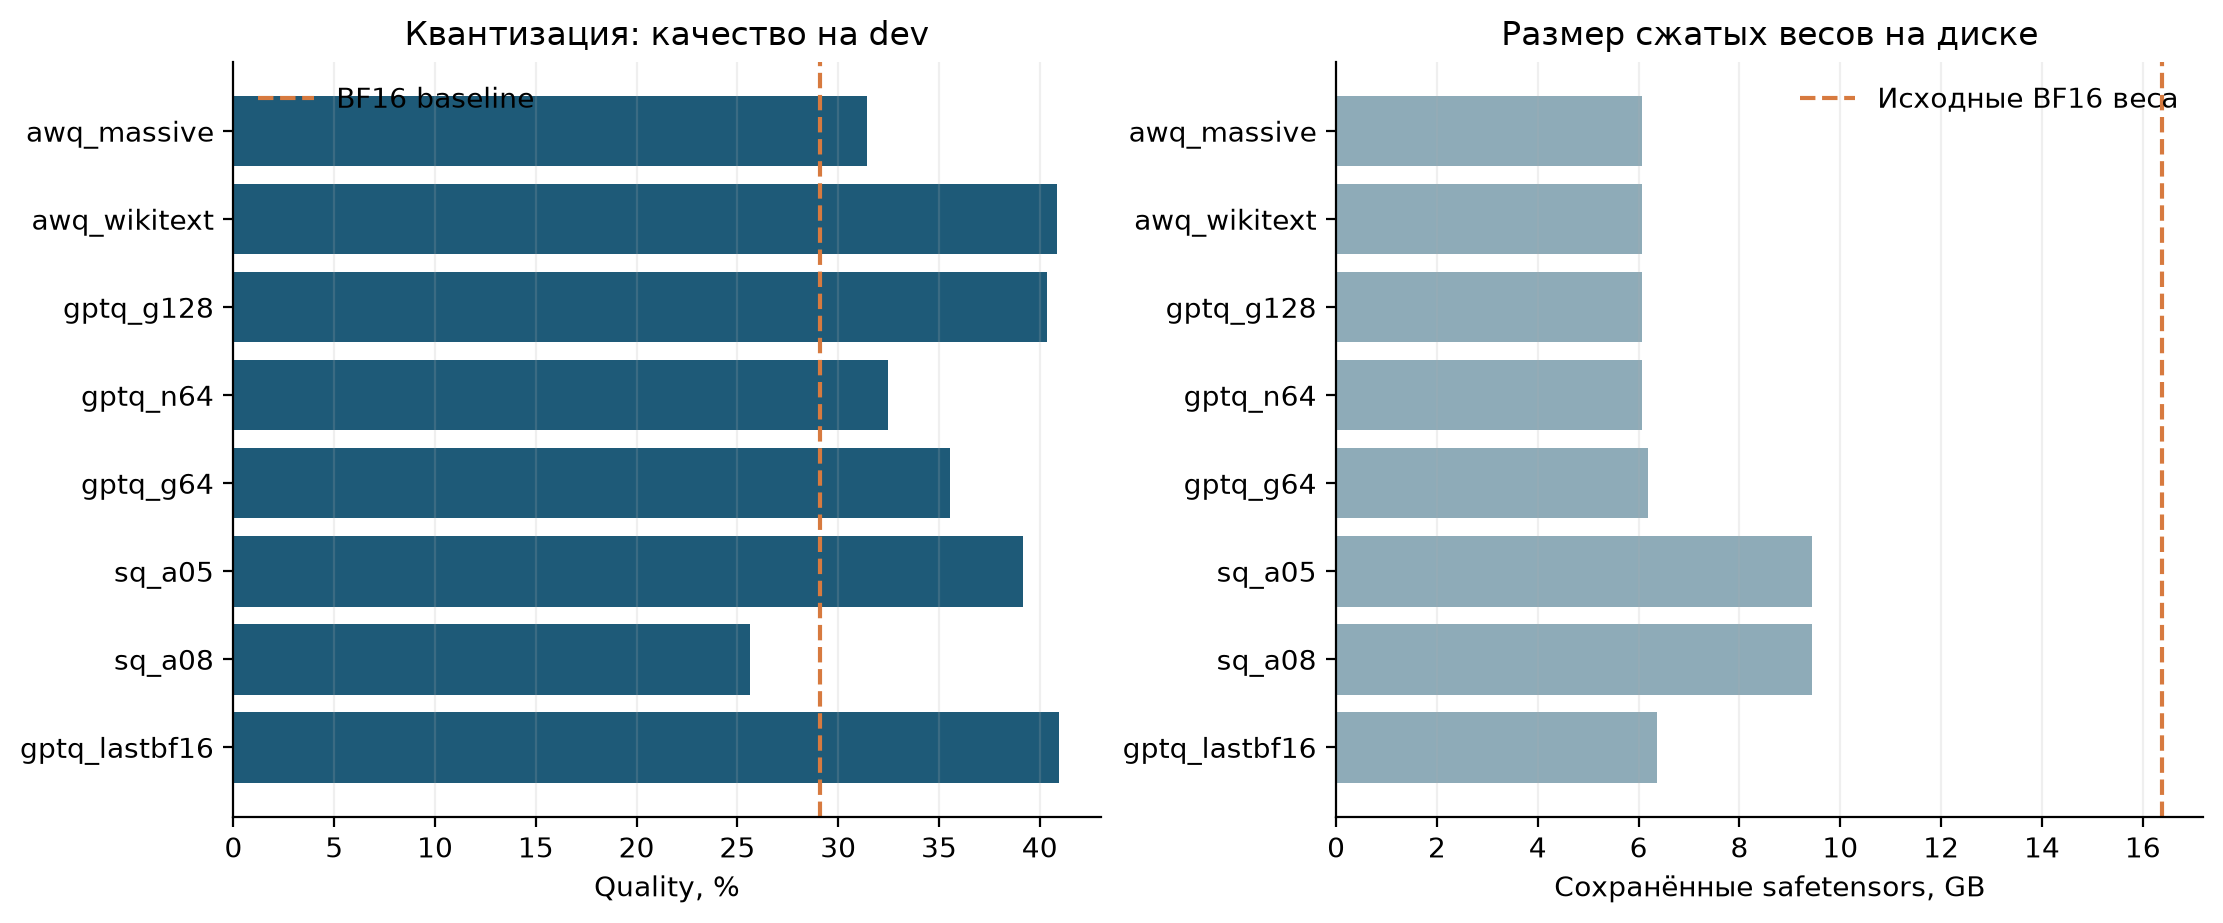

In [14]:
quant_results = []
for name in configs['quantization']:
    run_missing(['quantize.py', '--config', name], ARTIFACTS / 'quantization' / f'{name}.json')
    row = checked_metrics(name)
    metadata = json.loads((ARTIFACTS / 'quantization' / f'{name}.json').read_text())
    row.update(configs['quantization'][name])
    row.update({key: metadata[key] for key in ('checkpoint_bytes', 'disk_ratio')})
    quant_results.append(row)
display(pd.DataFrame(quant_results))
if Path('outputs/quantization.png').exists():
    display(Image(filename='outputs/quantization.png'))

### Выводы

При одинаковых 256 примерах AWQ на WikiText дал Quality 0.4088, на MASSIVE — 0.3141. Источник менялся вместе с числом токенов: 152499 против 128957. Результат относится к этим двум калибровочным наборам, без отдельного контроля языка и длины.

В GPTQ увеличение числа примеров с 64 до 256 подняло Quality с 0.3248 до 0.4037. Уменьшение group size до 64 не помогло: 0.3553. Последний блок в BF16 дал 0.4097. У SmoothQuant alpha=0.5 получено 0.3918, alpha=0.8 — 0.2564; увеличение smoothing ухудшило результат.

У AWQ и GPTQ g128 размер весов 6.071 GB вместо 16.382 GB исходных весов, W8A8 — 9.439 GB. Это размер safetensors на диске. Оценка выполняется с распакованными BF16-весами и сохранённой fake quantization; в W8A8 проверены также динамические 8-битные активации. Ускорение INT8-ядер не измерялось. Изменения JSON-валидности заметно влияют на Quality на этой небольшой dev-выборке.


## Hard-label дистилляция (5 баллов)

Теперь реализуем hard-label дистилляцию знаний от учителя **Qwen3-32B** в бейзлайн.

### Задания
1) Измерьте качество учителя на dev и сравните с бейзлайном: насколько учитель сильнее? (1 балл)
2) Получите жадные ответы учителя на сэмпле из train. Используйте батч для ускорения при необходимости (1 балл)
3) Реализуйте код для обучения ученика на ответах учителя (1 балл)
4) Проведите эксперименты с обучением, получите модель ученика, отклоняющуюся на dev не более чем на 10% от метрики учителя (2 балла)


### Измерим качество учителя и сравним с бейзлайном (1 балл)

In [15]:
print({'student': BASE_MODEL_ID, 'teacher': TEACHER_MODEL_ID, 'teacher_revision': TEACHER_REVISION})
print('Совпадение vocab/chat template/EOS/pad проверяется в collect_teacher_answers до генерации')

{'student': 'Qwen/Qwen3-8B', 'teacher': 'Qwen/Qwen3-32B', 'teacher_revision': '9216db5781bf21249d130ec9da846c4624c16137'}
Совпадение vocab/chat template/EOS/pad проверяется в collect_teacher_answers до генерации


In [16]:
run_missing(['distill.py', 'teacher'], ARTIFACTS / 'teacher_answers/manifest.json')

In [17]:
teacher_metrics = checked_metrics('teacher')
display(pd.DataFrame([baseline_metrics, teacher_metrics]))
print('Относительное целевое Q:', 0.9 * teacher_metrics['quality'])

,run,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,n
0,baseline,0.291174,0.382812,0.199536,0.109375,0.531250,256
1,teacher,0.582294,0.785156,0.379433,0.316406,0.976562,256


Относительное целевое Q: 0.5240649933510638


### Получим ответы учителя на трейне (1 балл)

Не забывайте выгружать модели и очищать память.

In [18]:
answers_path = ARTIFACTS / 'teacher_answers/answers.jsonl'
teacher_manifest = json.loads(answers_path.with_name('manifest.json').read_text())
assert hashlib.sha256(answers_path.read_bytes()).hexdigest() == teacher_manifest['sha256']
print({key: teacher_manifest[key] for key in ('n', 'valid', 'ended_eos', 'filtered', 'prompt_tokens', 'answer_tokens')})

{'n': 1024, 'valid': 1003, 'ended_eos': 1024, 'filtered': 0, 'prompt_tokens': 515841, 'answer_tokens': 21655}


In [19]:
answers = [json.loads(line) for line in answers_path.read_text().splitlines()]
assert len(answers) == 1024
assert [row['id'] for row in answers] == train_data.shuffle(seed=SEED).select(range(1024))['id']
print(json.dumps({key: answers[0][key] for key in ('id', 'text', 'gold', 'teacher_answer', 'ended_eos', 'truncated')}, ensure_ascii=False, indent=2))

{
  "id": "1847",
  "text": "закажи для меня чизбургер в ам бургере",
  "gold": "{\"intent\":\"takeaway_order\",\"slots\":[[\"food_type\",\"чизбургер\"],[\"business_name\",\"ам бургере\"]]}",
  "teacher_answer": "{\"intent\":\"takeaway_order\",\"slots\":[[\"food_type\",\"чизбургер\"],[\"business_name\",\"ам бургер\"]]}",
  "ended_eos": true,
  "truncated": false
}


### Реализация пайплайна обучения ученика (1 балл)

Полное дообучение Qwen3-8B на A100 80GB проходит на грани по памяти. Для решения можно включать gradient checkpointing, уменьшать batch или брать меньшую модель того же семейства.

In [20]:
dataset = TeacherAnswerDataset(answers_path, 128)
feature = dataset[0]
assert feature['labels'][:len(answers[0]['prompt_ids'])] == [-100] * len(answers[0]['prompt_ids'])
assert feature['labels'][len(answers[0]['prompt_ids']):] == answers[0]['answer_ids']
batch = collate_teacher_answers([dataset[0], dataset[1]], tokenizer.pad_token_id)
print({key: list(value.shape) for key, value in batch.items()})

{'input_ids': [2, 536], 'attention_mask': [2, 536], 'labels': [2, 536]}


In [21]:
run_missing(['distill.py', 'smoke'], ARTIFACTS / 'training/smoke/summary.json')
smoke = json.loads((ARTIFACTS / 'training/smoke/summary.json').read_text())
assert smoke['trainable_parameters'] == smoke['total_parameters']
assert smoke['optimizer']['foreach'] is False
assert smoke['tracked_weight_max_abs_delta'] > 0
print({key: smoke[key] for key in ('total_parameters', 'peak_allocated_bytes', 'peak_reserved_bytes', 'tracked_weight_max_abs_delta')})
print(smoke['optimizer'])

{'total_parameters': 8190735360, 'peak_allocated_bytes': 68095740416, 'peak_reserved_bytes': 68969037824, 'tracked_weight_max_abs_delta': 3.0517578125e-05}
{'gradient_dtypes': {'torch.bfloat16': 399}, 'optimizer_state_dtypes': {'torch.float32': 399, 'torch.bfloat16': 798}, 'foreach': False, 'parameter_dtypes': {'torch.bfloat16': 399}, 'optimizer_states': 399}


,run,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,n,samples,epochs,learning_rate
0,s128,0.462798,0.687500,0.238095,0.105469,0.945312,256,128,1,0.00002
1,s1024,0.605927,0.781250,0.430605,0.339844,0.980469,256,1024,1,0.00002
2,s1024_e3,0.611377,0.789062,0.433692,0.339844,0.976562,256,1024,3,0.00002


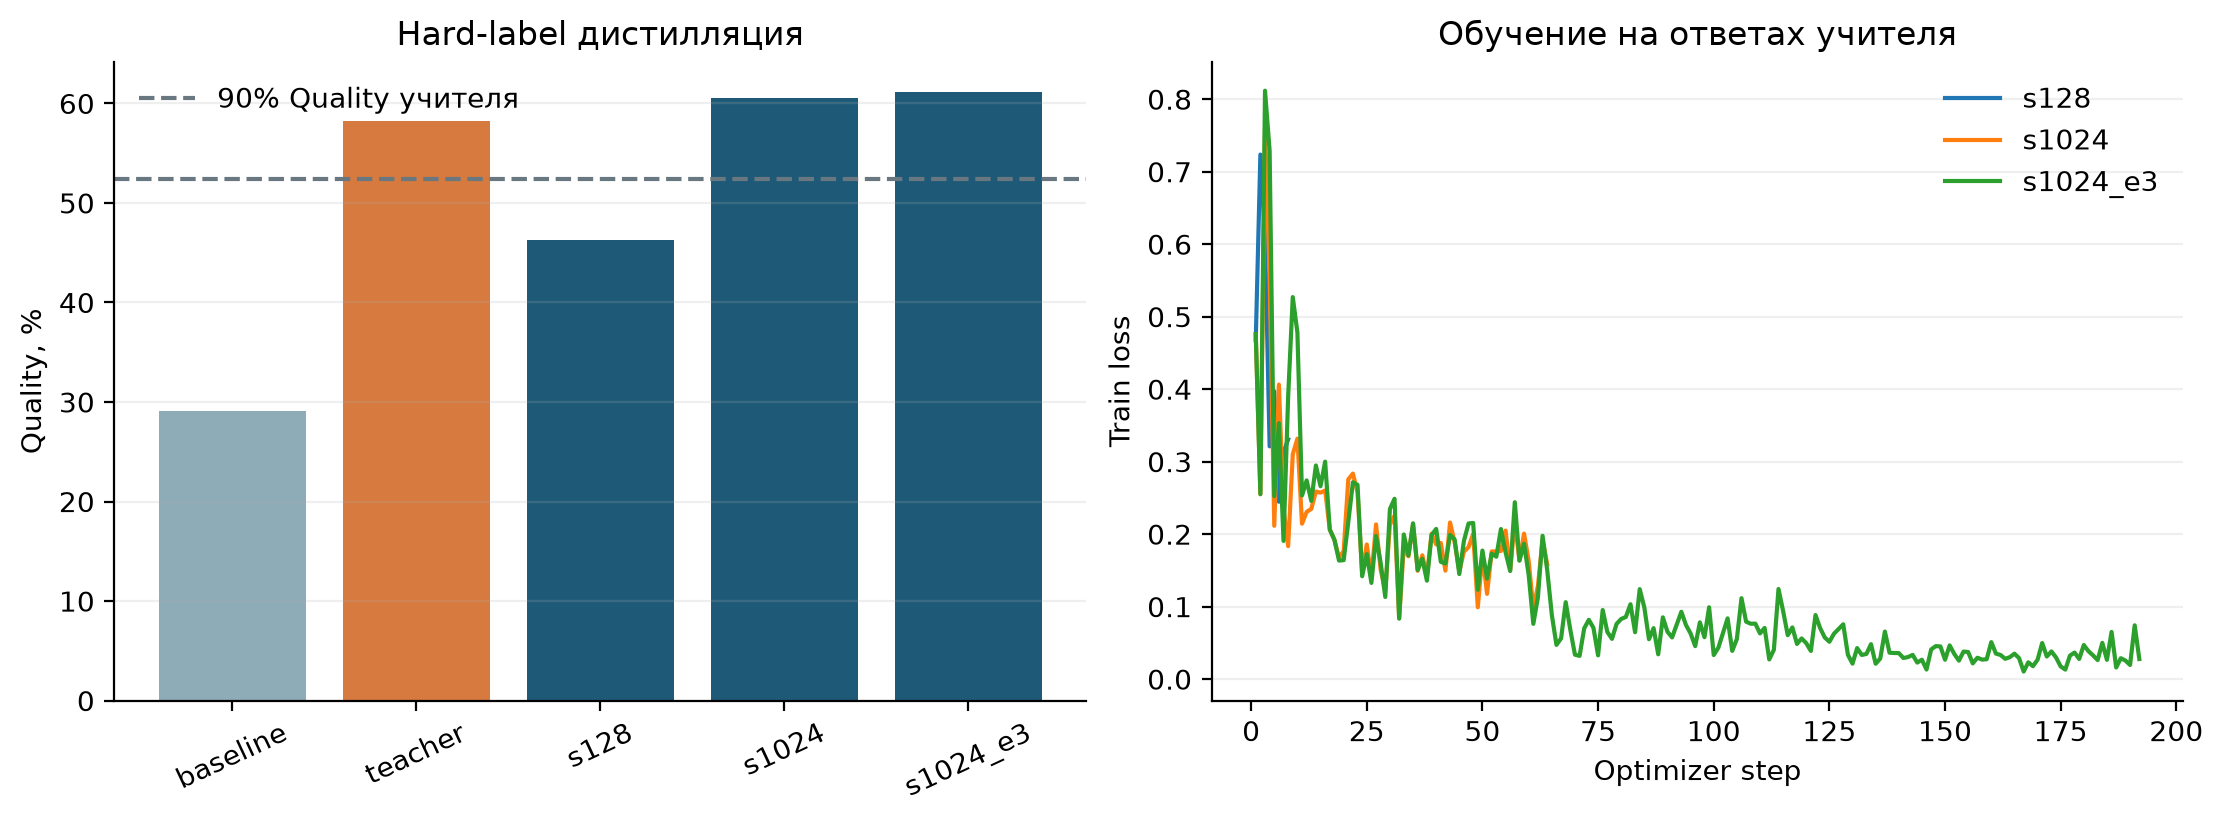

In [22]:
student_results = []
for name in ('s128', 's1024', 's1024_e3'):
    run_missing(['distill.py', 'train', '--config', name], ARTIFACTS / 'evaluations' / f'{name}.json')
    row = checked_metrics(name)
    row.update(configs['distillation'][name])
    student_results.append(row)
display(pd.DataFrame(student_results))
if Path('outputs/distillation.png').exists():
    display(Image(filename='outputs/distillation.png'))

### Добейтесь максимального качества ученика. Цель — не более 10% отклонения от учителя (2 балла)
Пробуйте менять гиперпараметры, число сэмплов, модели ученика (при условии размера модели ученика не более 8B).

In [23]:
best = max(student_results, key=lambda row: row['quality'])
run_missing(['distill.py', 'select'], ARTIFACTS / 'student_selection.json')
selection = json.loads((ARTIFACTS / 'student_selection.json').read_text())
assert selection['selected_run'] == best['run']
print({'selected': best['run'], 'student_quality': best['quality'], 'teacher_quality': teacher_metrics['quality'], 'relative_quality': best['quality'] / teacher_metrics['quality'], 'target_met': best['quality'] >= 0.9 * teacher_metrics['quality'], 'above_baseline': best['quality'] > baseline_metrics['quality']})

{'selected': 's1024_e3', 'student_quality': 0.6113771281362007, 'teacher_quality': 0.5822944370567376, 'relative_quality': 1.0499449921357042, 'target_met': True, 'above_baseline': True}


### Выводы

Увеличение числа ответов учителя со 128 до 1024 при одной эпохе подняло Quality с 0.4628 до 0.6059. Три эпохи дали 0.6114: дополнительный выигрыш заметно меньше, 0.0054. Выбран s1024_e3, исходная Qwen3-8B дообучена целиком.

Quality учителя — 0.5823, исходной модели — 0.2912. Ученик получил 104.99% Quality учителя; порог 90% равен 0.5241 и достигнут. Это результат на фиксированных 256 dev-примерах, по которым выбирались настройки. Test не использовался; преимущество за пределами этой выборки не утверждается. Все 1024 ответа учителя, включая 21 невалидный, сохранены без исправления JSON и без замены эталонами.
